In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [11]:

df = pd.read_csv('/content/data_YesBank_StockPrices.csv')

In [12]:
df.head()

,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


In [13]:
df.tail()

,Date,Open,High,Low,Close
180,Jul-20,25.60,28.30,11.10,11.95
181,Aug-20,12.00,17.16,11.85,14.37
182,Sep-20,14.30,15.34,12.75,13.15
183,Oct-20,13.30,14.01,12.11,12.42
184,Nov-20,12.41,14.90,12.21,14.67


In [9]:
df.shape

(185, 5)

In [7]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB


In [8]:
df.duplicated().sum()

np.int64(0)

In [15]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Date     0.0
Open     0.0
High     0.0
Low      0.0
Close    0.0
dtype: float64


In [16]:
plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

<Axes: >

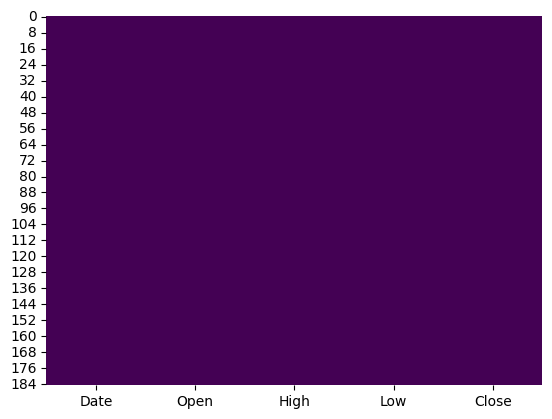

In [17]:
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

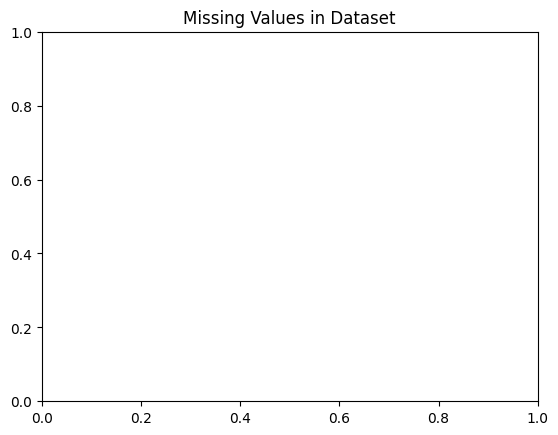

In [18]:
plt.title("Missing Values in Dataset")
plt.show()

In [19]:
print(df.columns)

Index(['Date', 'Open', 'High', 'Low', 'Close'], dtype='object')


In [20]:

df.describe()

,Open,High,Low,Close
count,185.000000,185.000000,185.000000,185.000000
mean,105.541405,116.104324,94.947838,105.204703
std,98.879850,106.333497,91.219415,98.583153
min,10.000000,11.240000,5.550000,9.980000
25%,33.800000,36.140000,28.510000,33.450000
50%,62.980000,72.550000,58.000000,62.540000
75%,153.000000,169.190000,138.350000,153.300000
max,369.950000,404.000000,345.500000,367.900000


In [21]:
for column in df.columns:
    print(column, ":", df[column].dtype)

Date : object
Open : float64
High : float64
Low : float64
Close : float64


In [22]:
for column in df.columns:
    print("\nColumn:", column)
    print("Unique Values:", df[column].unique())


Column: Date
Unique Values: ['Jul-05' 'Aug-05' 'Sep-05' 'Oct-05' 'Nov-05' 'Dec-05' 'Jan-06' 'Feb-06'
 'Mar-06' 'Apr-06' 'May-06' 'Jun-06' 'Jul-06' 'Aug-06' 'Sep-06' 'Oct-06'
 'Nov-06' 'Dec-06' 'Jan-07' 'Feb-07' 'Mar-07' 'Apr-07' 'May-07' 'Jun-07'
 'Jul-07' 'Aug-07' 'Sep-07' 'Oct-07' 'Nov-07' 'Dec-07' 'Jan-08' 'Feb-08'
 'Mar-08' 'Apr-08' 'May-08' 'Jun-08' 'Jul-08' 'Aug-08' 'Sep-08' 'Oct-08'
 'Nov-08' 'Dec-08' 'Jan-09' 'Feb-09' 'Mar-09' 'Apr-09' 'May-09' 'Jun-09'
 'Jul-09' 'Aug-09' 'Sep-09' 'Oct-09' 'Nov-09' 'Dec-09' 'Jan-10' 'Feb-10'
 'Mar-10' 'Apr-10' 'May-10' 'Jun-10' 'Jul-10' 'Aug-10' 'Sep-10' 'Oct-10'
 'Nov-10' 'Dec-10' 'Jan-11' 'Feb-11' 'Mar-11' 'Apr-11' 'May-11' 'Jun-11'
 'Jul-11' 'Aug-11' 'Sep-11' 'Oct-11' 'Nov-11' 'Dec-11' 'Jan-12' 'Feb-12'
 'Mar-12' 'Apr-12' 'May-12' 'Jun-12' 'Jul-12' 'Aug-12' 'Sep-12' 'Oct-12'
 'Nov-12' 'Dec-12' 'Jan-13' 'Feb-13' 'Mar-13' 'Apr-13' 'May-13' 'Jun-13'
 'Jul-13' 'Aug-13' 'Sep-13' 'Oct-13' 'Nov-13' 'Dec-13' 'Jan-14' 'Feb-14'
 'Mar-14' 'Apr-14' 'Ma

In [23]:
df.nunique()

,0
Date,185
Open,183
High,184
Low,183
Close,185


In [24]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


In [25]:
df.drop_duplicates(inplace=True)

In [26]:
print(df.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


In [27]:
print(df.dtypes)

Date      object
Open     float64
High     float64
Low      float64
Close    float64
dtype: object


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB


In [29]:
df.head()

,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


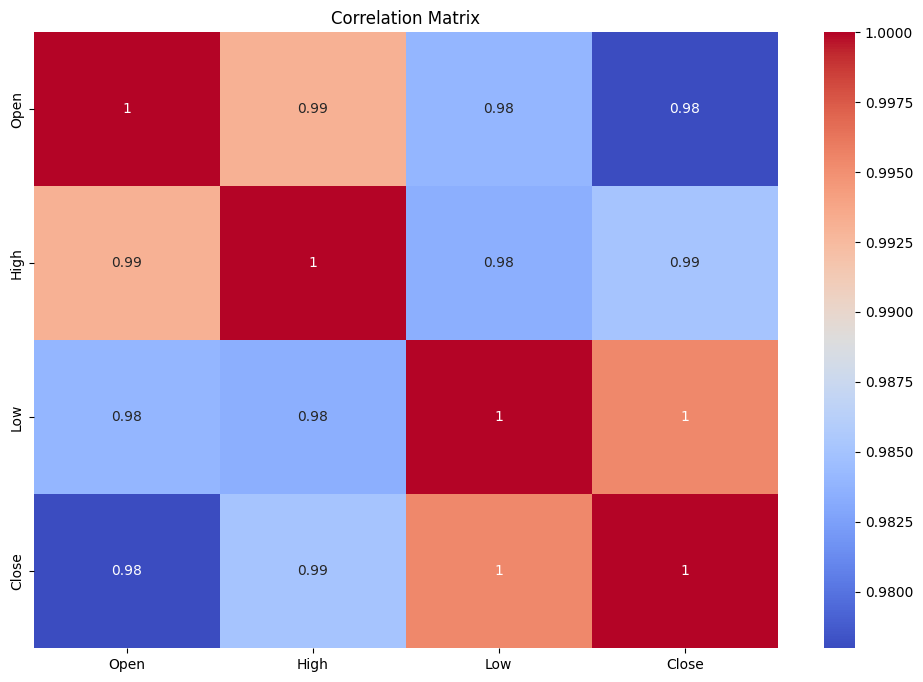

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

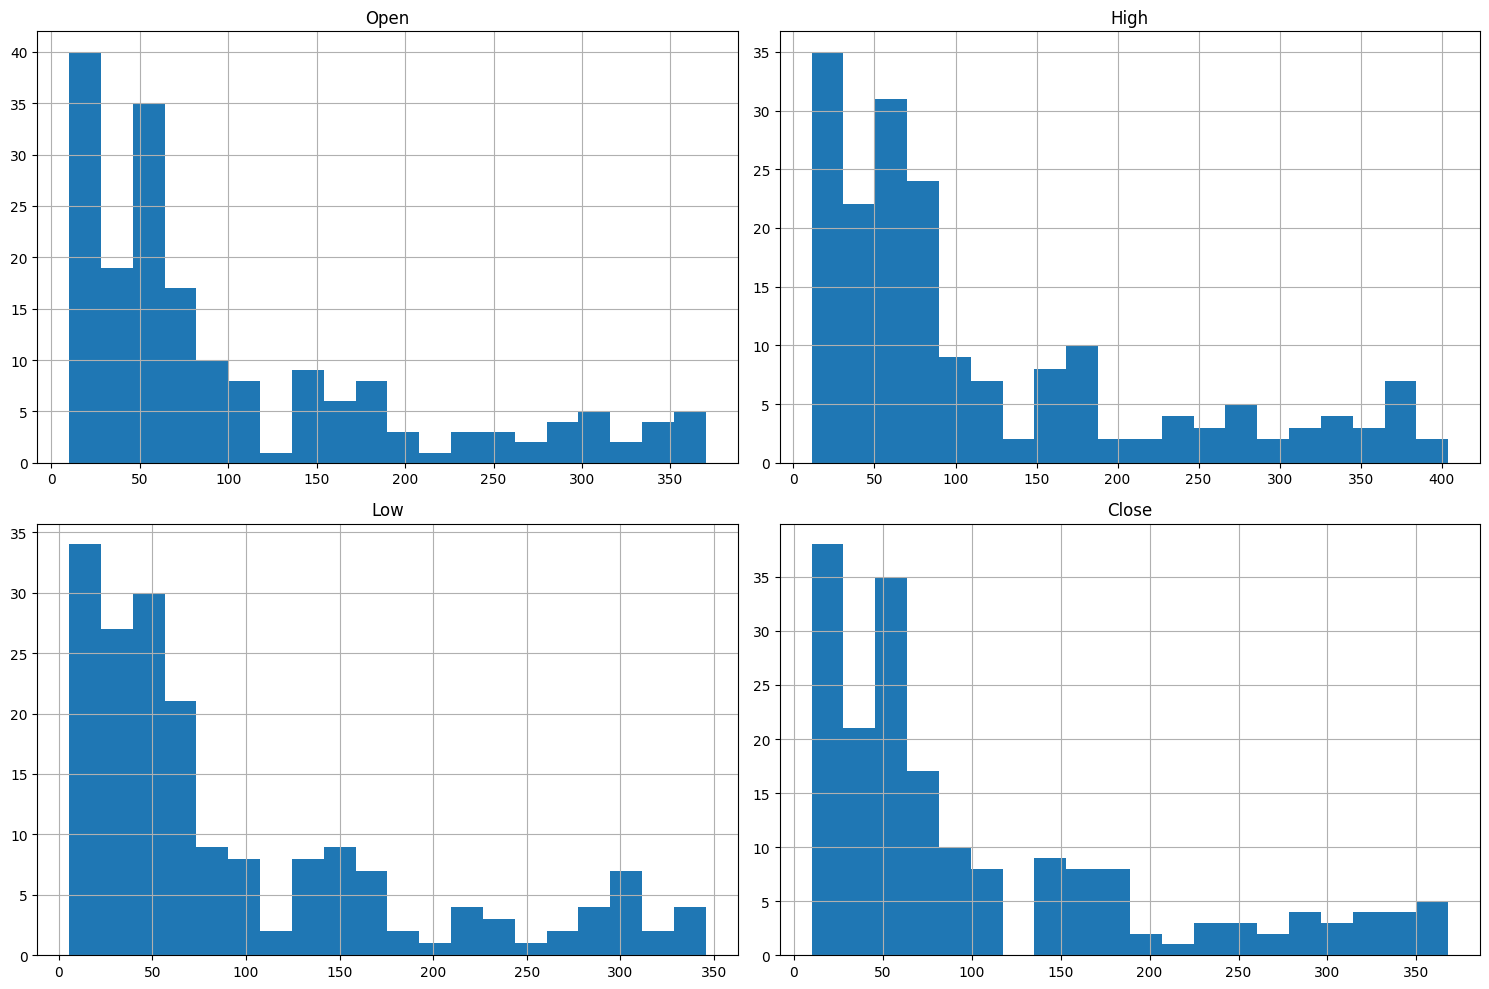

In [31]:
df.hist(figsize=(15, 10), bins=20)

plt.tight_layout()
plt.show()

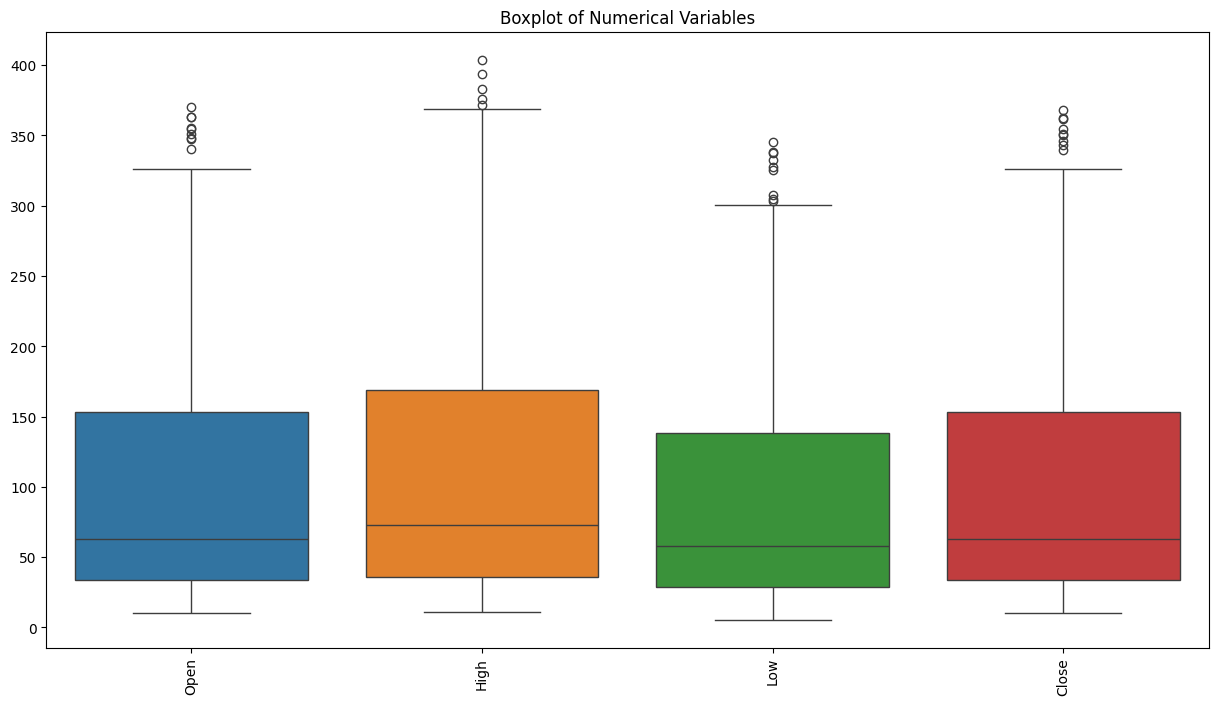

In [33]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df)

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Variables")
plt.show()

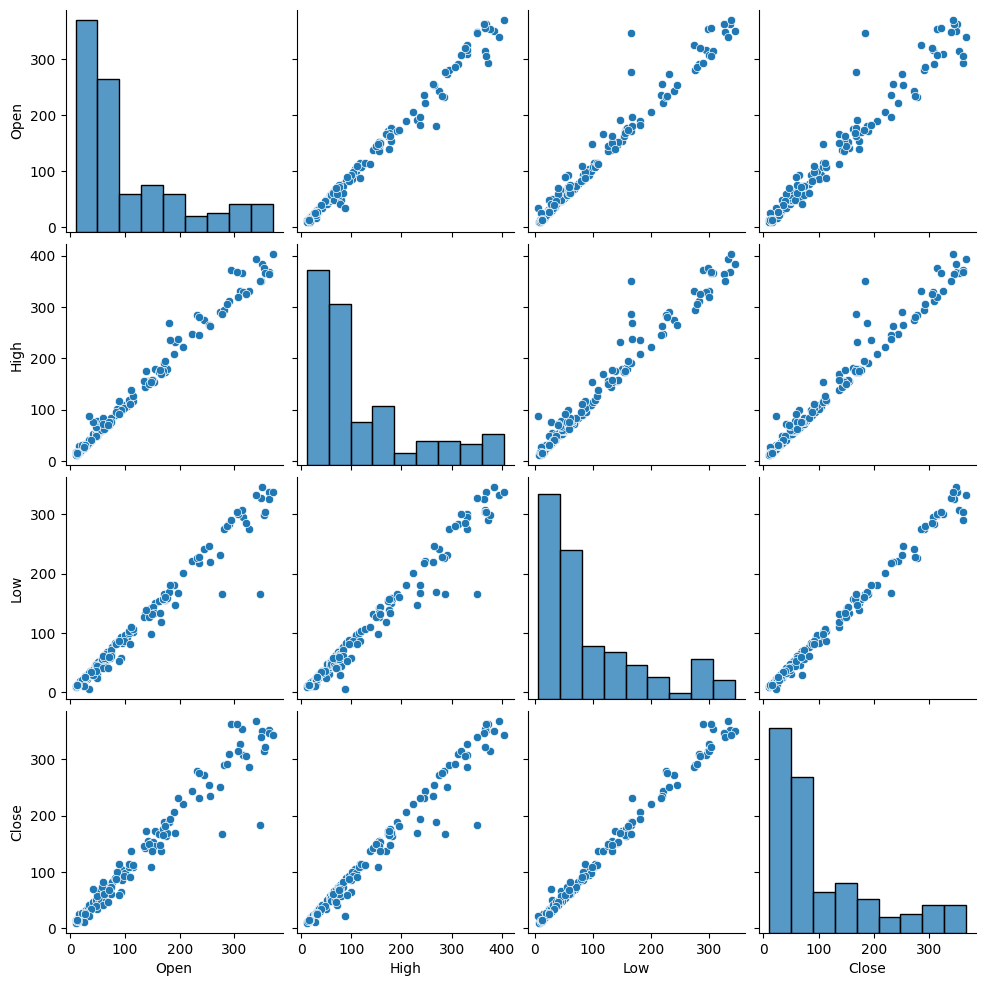

In [34]:

sns.pairplot(df.select_dtypes(include='number'))

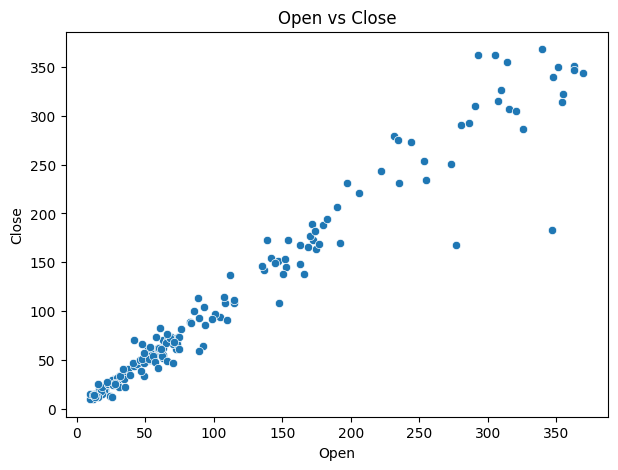

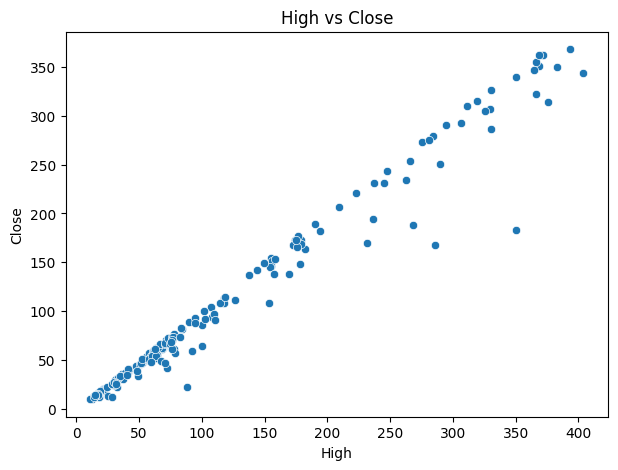

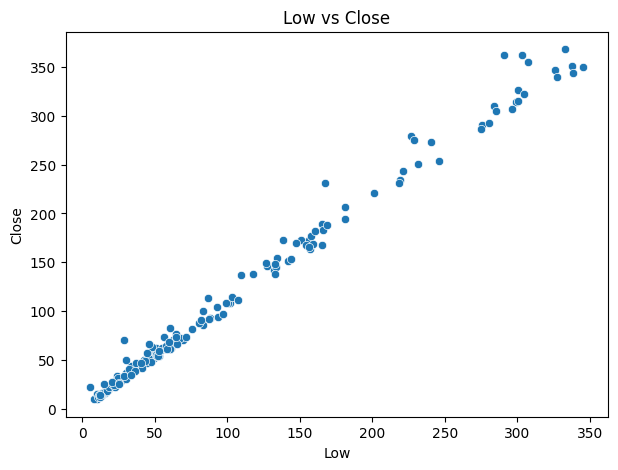

In [35]:
numeric_columns = df.select_dtypes(include='number').columns

for column in numeric_columns:
    if column != numeric_columns[-1]:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=df, x=column, y=numeric_columns[-1])
        plt.title(f"{column} vs {numeric_columns[-1]}")
        plt.show()

In [37]:
X = df.drop(columns=['Date', 'Close'])
y = df['Close']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (185, 3)
Target shape: (185,)


In [39]:
X = df.drop(columns=['Date', 'Close'])
y = df['Close']

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (148, 3)
X_test: (37, 3)
y_train: (148,)
y_test: (37,)


In [41]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Features:")
print(numeric_features)

Numerical Features:
Index(['Open', 'High', 'Low'], dtype='object')


In [42]:

categorical_features = X.select_dtypes(include=['object']).columns

print("Categorical Features:")
print(categorical_features)

Categorical Features:
Index([], dtype='object')


In [43]:
X = pd.get_dummies(X, drop_first=True)

print(X.head())

    Open   High    Low
0  13.00  14.00  11.25
1  12.58  14.88  12.55
2  13.48  14.87  12.27
3  13.20  14.47  12.40
4  13.35  13.88  12.88


In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [45]:
print(df.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close']


In [46]:
from sklearn.linear_model import LinearRegression

In [47]:
lr_model = LinearRegression()

In [48]:
lr_model.fit(X_train, y_train)

LinearRegression()

In [50]:
y_pred_lr = lr_model.predict(X_test)
print("Linear Regression completed successfully!")

Linear Regression completed successfully!


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE : 5.812554509942107
MSE : 86.64379126513752
RMSE: 9.30826467528387
R2 Score: 0.9904142726548665


In [52]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest completed successfully!")

Random Forest completed successfully!


In [53]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE : 8.725616216216203
MSE : 190.73458356054064
RMSE: 13.810669193074629
R2 Score: 0.9788983181991185


In [54]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, mae_rf],
    'RMSE': [rmse, rmse_rf],
    'R2 Score': [r2, r2_rf]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.812555,9.308265,0.990414
1,Random Forest,8.725616,13.810669,0.978898


In [55]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_rf
})

comparison.head(10)

,Actual,Predicted
19,28.63,31.9443
42,12.24,12.8637
156,367.90,343.4839
111,136.83,112.6256
148,306.80,317.8229
15,22.78,19.4788
24,37.93,41.1938
68,61.98,58.6641
117,167.96,168.7129
98,57.50,67.4942


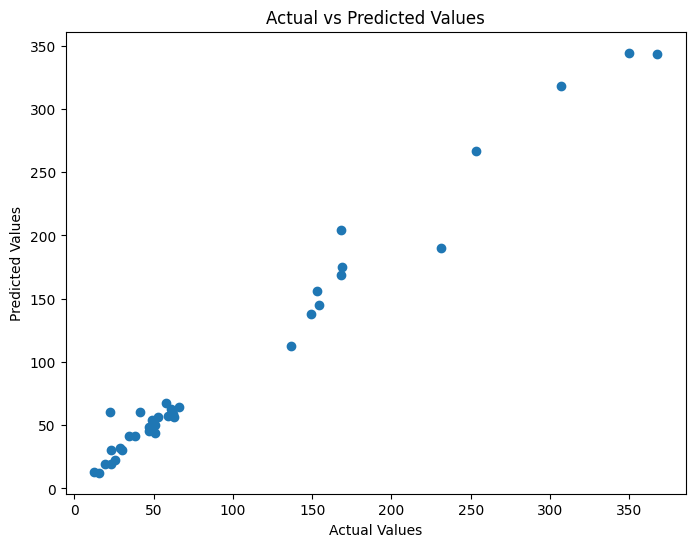

In [56]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.show()